# Simulated: noise survey and normal vs streamed sweeps

The same steps as `CF_noise_survey.ipynb`, run against fake SR860s and a fake gated device
that stream UDP on this PC, so no instruments are needed. The numbers are made up and the
runs are shorter. The fake device has a broad peak at +0.25 V and a sharp one at −0.55 V
with a 20 ms gate-line RC. The fake lock-ins start at τ = 300 ms (24 dB/oct). Live plots
(`s.plot`) work as in measureme but are left out here.

In [1]:
import os
import sweep
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import dmz_measure as dm
from dmz_measure.simulate import fake_cryofree, FakeGate

os.makedirs('./data_sim', exist_ok=True)
sweep.set_basedir('./data_sim')

fakes = fake_cryofree()
SR860_A, SR860_B, SR860_C, Kbg2 = fakes['SR860_A'], fakes['SR860_B'], fakes['SR860_C'], fakes['Kbg2']
Ktg2 = FakeGate('Ktg2')
for gate in (Kbg2, Ktg2):        # like the real Keithleys: 5 mV chunks, 5 ms apart,
    gate.volt.step = 0.005       # 20 ms per command, 20 ms per current reading
    gate.volt.inter_delay = 0.005

C:\Users\declan\miniconda3\envs\dmz\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
measurement_config = {
    'SR860_A': '9-12',
    'SR860_B': '15-14',
    'SR860_C': '15-11',
    'Vbg2': '13',
    'Vtg2': '16'
}

SR860s = [(SR860_A, 1E6), (SR860_B, 100), (SR860_C, 100)]

In [3]:
SR860_A.amplitude(0)   # excitation off (by hand on the real setup)

Saved lock-in settings (restored automatically when done):
  SR860_A: RSRC=0, OFLT=11, OFSL=3, SYNC=0, ADVFILT=0, HARM=1, FREQ=13.2943
  SR860_B: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=0, HARM=1, FREQ=13.2943
  SR860_C: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=0, HARM=1, FREQ=13.2943


Streaming SR860_A, SR860_B, SR860_C for 40 s at 9765.62 Hz (f_ref 100 Hz, tau 100 us) ...


streaming:   0%|          | 0/40 [00:00<?, ?s/s]

streaming:   2%|▎         | 1/40 [00:00<00:23,  1.66s/s]

streaming:   2%|▎         | 1/40 [00:00<00:23,  1.66s/s, packets=139]

streaming:   5%|▌         | 2/40 [00:01<00:31,  1.19s/s, packets=139]

... (75 outputs left out)

streaming: 100%|██████████| 40/40 [00:39<00:00,  1.05s/s, packets=8856]

streaming: 100%|██████████| 40/40 [00:39<00:00,  1.05s/s, packets=9042]

  SR860_A: 390528 samples, 40.0 s at 9765.62 Hz, 3051 packets, no drops/flags
  SR860_B: 390528 samples, 40.0 s at 9765.62 Hz, 3051 packets, no drops/flags
  SR860_C: 390528 samples, 40.0 s at 9765.62 Hz, 3051 packets, no drops/flags
Lock-in settings restored.


Saved run 0 in ./data_sim
Noise survey (run 0): SR860_A, SR860_B, SR860_C
  f_ref 100 Hz, 40 s, band 0-200 Hz, bins 0.298 Hz, tau 100 us, mains 60 Hz
  SR860_A: floor 2.04 pA/√Hz (22 averages)
  SR860_B: floor 10.4 nV/√Hz (22 averages)
  SR860_C: floor 16.1 nV/√Hz (22 averages)
  strongest lines (Hz): 60.06 (mains), 119.97 (mains x2), 179.87 (mains x3)


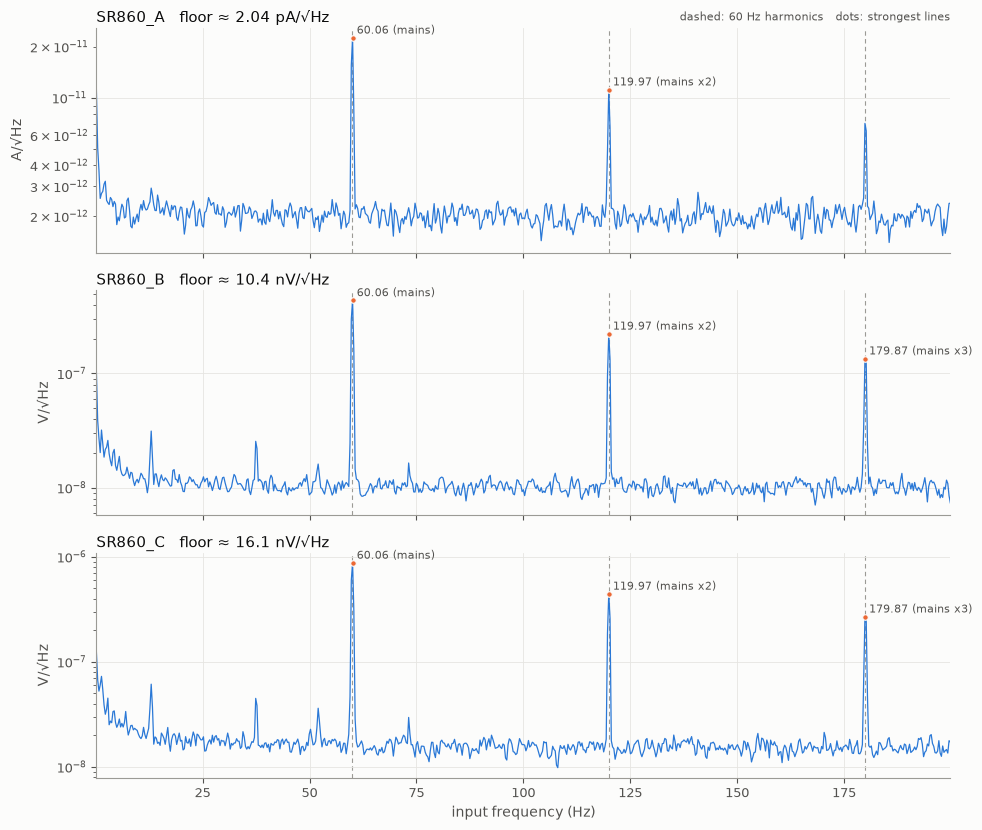

In [4]:
s = dm.AsyncStation(measurement_config)
s.add_comment('noise survey, excitation off')
for SR860, gain in SR860s:
    s.fp(SR860.X, gain=gain)
    s.fp(SR860.Y, gain=gain)

survey = s.noise_survey(
    current='SR860_A',  #     lock-in that measures the current
    f_ref=100,          # Hz  reference frequency during the survey
    duration=40,       # s   streaming time (longer = smoother spectra, more time blocks)
    fmin=0, fmax=200,   # Hz  band to keep (anything from 0 to f_ref + rate/2 works)
    resolution=0.25,   # Hz  FFT bin width: Welch segments of 1/resolution s, 50 % overlap
    tau=100e-6,         # s   lock-in time constant during the survey (<= 100 us keeps the band flat)
    rate=10e3,          # Hz  stream rate
)
survey.plot();

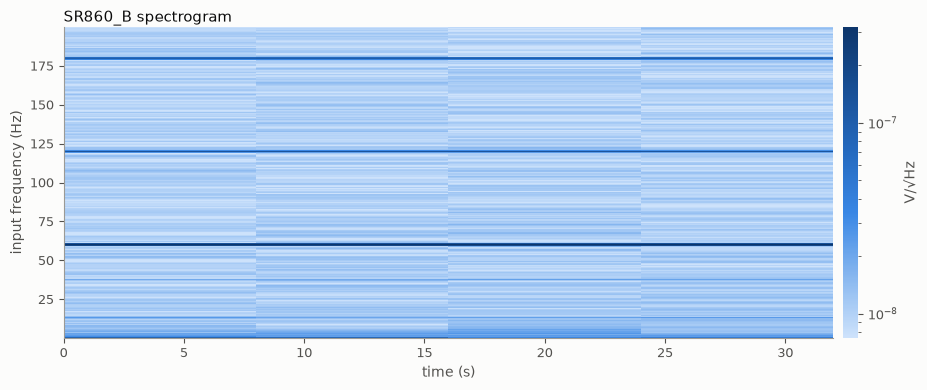

In [5]:
survey.spectrogram('SR860_B', block=8);   # noise vs time: look for bursts (compressor, pumps, ...)

## 2. Choose frequencies (analysis only; rerun as often as you like)

`best_frequencies` predicts the noise of one data point at every reference frequency in
`[fmin, fmax]`, for the filter that makes one data point:
* **Normal measurement (`s.sweep`):** the SR860 time constant (`tau`, `slope`, `advanced`
  = the Advanced/Gaussian filter, `sync`), read once (`dwell=None`).
* **Streamed (`s.stream_sweep`):** a short `tau` with `sync=True`, plus a software average
  over `dwell` seconds, weighted with `window` (`'hann'` or `'boxcar'`).

To account for noise that comes and goes, the survey is cut into `block`-second pieces and
the prediction is made for each piece. `stat='p90'` ranks by the noise exceeded 10 % of
the time. In the table, **spread** = worst block / typical block; the line above the table
gives the value steady noise produces. `expected_noise` gives the numbers for frequencies
you type in. A saved survey can be reloaded with `survey = dm.load_survey(<run ID>)`.

Best frequencies 10-40 Hz for tau=300 ms 24 dB/oct, ranked by p90 over 10 s blocks
  noise = predicted rms of one reading (input referred)
  spread = worst block / typical block; steady noise gives about 1.13 here, clearly more = intermittent noise
  #   f (Hz) |   SR860_A noise spread |   SR860_B noise spread |   SR860_C noise spread
  1    25.80 |         1.23 pA   1.07 |         5.15 nV   1.14 |         7.26 nV   1.00
  2    38.61 |         1.11 pA   1.04 |         5.09 nV   1.02 |         8.22 nV   1.11
  3    30.86 |         1.11 pA   1.42 |         5.35 nV   1.14 |         8.97 nV   1.16
  4    24.60 |          969 fA   1.06 |         6.57 nV   1.01 |         8.35 nV   1.01
  5    29.07 |         1.21 pA   1.15 |         5.85 nV   1.54 |         7.86 nV   1.08


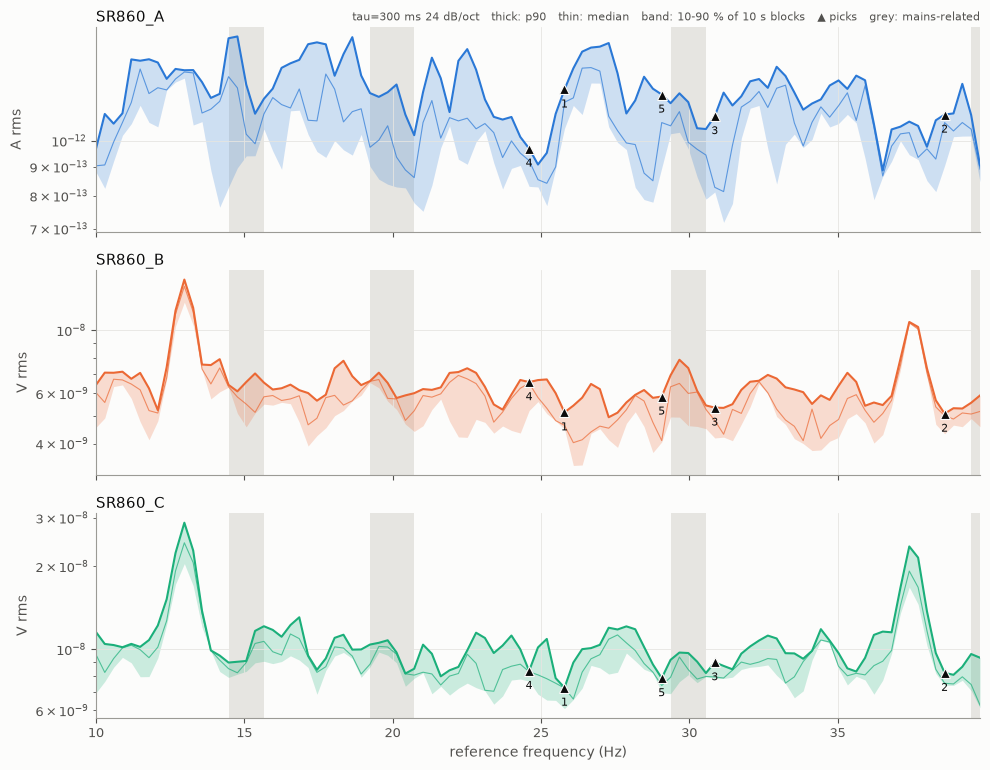

In [6]:
best = dm.best_frequencies(
    survey,
    fmin=10, fmax=40,       # Hz  range to search
    tau=0.3, slope=24,      # lock-in time constant (s) and slope (dB/oct) you will measure with
    advanced=False,         #     SR860 Advanced (Gaussian) filter on?  check: SR860_A.ask('ADVFILT?')
    sync=False,             #     sync filter
    dwell=None,             # s   software average per data point (None = one reading)
    window='boxcar',        #     weighting of that average: 'boxcar' or 'hann'
    n=5, min_spacing=1.0,   #     how many to return, minimum spacing (Hz)
    avoid_mains=True,       #     skip mains * p/q (15, 20, 30, 40, 45 ... Hz at 60 Hz mains)
    block=10, stat='p90',  # s   time blocks; rank by 'mean', 'median', 'p90' or 'max'
)
best.plot();

In [7]:
freqs = [SR860_A.frequency(), 17.777, 23.3]   # Hz, any frequencies

# normal measurement: one reading with the SR860 filter
dm.expected_noise(survey, freqs, tau=0.3, slope=24, advanced=False, sync=False, dwell=None,
                  block=10)
# streamed: tau ~ 1 ms + sync, Hann-weighted 0.3 s average per point
dm.expected_noise(survey, freqs, tau=1e-3, slope=24, sync=True, dwell=0.3, window='hann',
                  block=10);

Expected noise for tau=300 ms 24 dB/oct (rms of one reading, input referred; p90 and worst over 10 s blocks)
   f (Hz) |   SR860_A mean       p90     worst |   SR860_B mean       p90     worst |   SR860_C mean       p90     worst
   13.294 |        1.34 pA   1.33 pA   1.34 pA |        10.2 nV   11.7 nV   11.8 nV |        19.9 nV   22.3 nV   22.8 nV
   17.777 |        1.14 pA   1.47 pA    1.5 pA |        5.92 nV      6 nV   6.02 nV |        9.21 nV   9.38 nV   9.55 nV
   23.300 |        1.02 pA    1.1 pA   1.11 pA |        5.52 nV    5.8 nV      6 nV |        9.31 nV   10.1 nV   10.9 nV


Expected noise for tau=1 ms 24 dB/oct, sync, dwell=300 ms Hann (rms of one reading, input referred; p90 and worst over 10 s blocks)
   f (Hz) |   SR860_A mean       p90     worst |   SR860_B mean       p90     worst |   SR860_C mean       p90     worst
   13.294 |        3.58 pA   3.69 pA   3.75 pA |        22.4 nV   23.8 nV     24 nV |        40.7 nV   43.4 nV   44.4 nV
   17.777 |        3.38 pA    3.6 pA   3.61 pA |        18.4 nV   19.6 nV   20.2 nV |        29.3 nV   30.4 nV   30.6 nV
   23.300 |        3.26 pA   3.41 pA   3.47 pA |        17.4 nV   18.4 nV   18.5 nV |        28.4 nV   28.4 nV   28.6 nV


In [8]:
SR860_A.amplitude(1.0)   # excitation back on (by hand on the real setup)

Saved lock-in settings (restored automatically when done):
  SR860_A: RSRC=0, OFLT=11, OFSL=3, SYNC=0, ADVFILT=0, HARM=1, FREQ=13.2943
  SR860_B: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=0, HARM=1, FREQ=13.2943
  SR860_C: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=0, HARM=1, FREQ=13.2943



25.7952 Hz: tau 1 ms, 24 dB/oct, sync on, 4 s


streaming:   0%|          | 0/4 [00:00<?, ?s/s]

streaming:  25%|██▌       | 1/4 [00:00<00:01,  1.66s/s]

streaming:  25%|██▌       | 1/4 [00:00<00:01,  1.66s/s, packets=141]

streaming:  50%|█████     | 2/4 [00:01<00:01,  1.19s/s, packets=141]

... (36 outputs left out)

streaming: 100%|██████████| 4/4 [00:03<00:00,  1.05s/s, packets=598]

streaming: 100%|██████████| 4/4 [00:03<00:00,  1.05s/s, packets=828]

  SR860_A: 39168 samples, 4.0 s at 9765.62 Hz, 306 packets, no drops/flags
  SR860_B: 39168 samples, 4.0 s at 9765.62 Hz, 306 packets, no drops/flags
  SR860_C: 39168 samples, 4.0 s at 9765.62 Hz, 306 packets, no drops/flags
Lock-in settings restored.


Saved run 1 in ./data_sim

Frequency check (run 1): noise = scatter of 0.3 s Hann-weighted averages relative to the value; worst = worst 2 s stretch
   f (Hz)     tau  adv sync |     SR860_A I    noise    worst  phase |     SR860_B R    noise    worst  phase |     SR860_C R    noise    worst  phase
  25.7952    1 ms  off   on |        100 nA 0.00242% 0.00282%   0.0° |         996 Ω  0.0143%  0.0186%  -3.7° |         594 Ω  0.0369%  0.0492%  -5.9°
  38.6102  300 us  off   on |        100 nA 0.00234% 0.00302%  -0.0° |         991 Ω   0.017%  0.0202%  -5.5° |         586 Ω  0.0798%  0.0689%  -8.8°
  30.8616    1 ms  off   on |        100 nA 0.00336% 0.00422%   0.0° |         994 Ω  0.0193%  0.0236%  -4.4° |         591 Ω  0.0416%  0.0452%  -7.0°
  13.2943    1 ms  off   on |        100 nA 0.00447% 0.00525%   0.0° |         999 Ω  0.0197%  0.0219%  -1.9° |         598 Ω  0.0749%  0.0572%  -3.0°


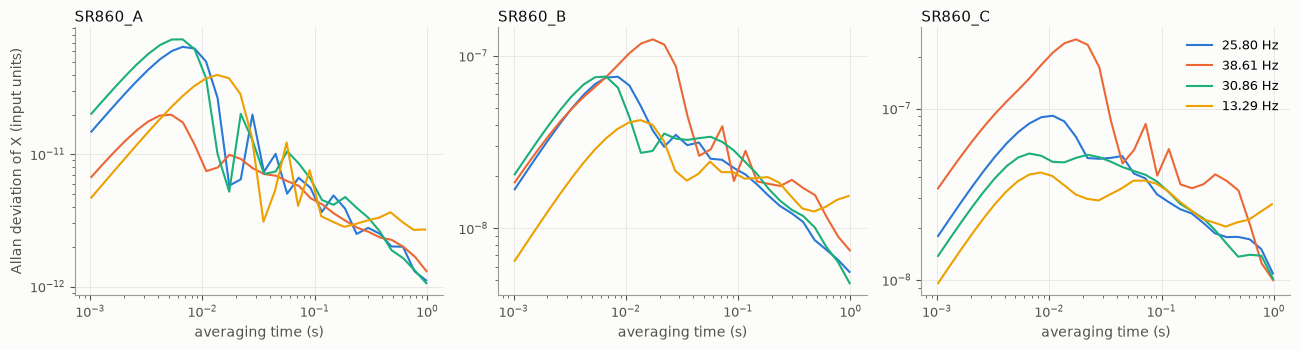

In [9]:
check = s.check_frequencies(
    best.frequencies[:3] + [SR860_A.frequency()],   # any list (Hz): here the top 3 + the one in use
    current='SR860_A',
    tau=None,           # s   None = largest SR860 value <= 1/(30 f) for each frequency
    slope=24,           #     dB/oct
    advanced=None,      #     Advanced filter on/off; None = leave as set
    sync=True,          #     sync filter
    duration=4,       # s   streamed per frequency
    dwell=0.3,          # s   averaging per data point; noise = scatter of these averages
    window='hann',      #     weighting of that average: 'hann' or 'boxcar'
    block=2,           # s   stretch length for the 'worst' column
)
check.plot();   # Allan deviation: keeps falling as 1/sqrt(time) while averaging still helps

## 4. Back-gate line sweeps: normal vs streamed

The same station does both. `s.sweep` is measureme's sweep, unchanged: set the gate, wait
`delay`, read every followed parameter once, with the lock-ins exactly as they are set.

`s.stream_sweep` writes the same columns, live plots and files. The followed SR860
X/Y/R/P values come from the stream: τ ≈ 1/(30 f) + sync, and each point is the
`window`-weighted average of the `dwell` seconds after `settle`. Every other followed
parameter (gate leakage etc.) is read as usual. The lock-in settings are restored
afterwards and the excitation is never touched. The stream is saved with the run, so
`dm.refilter(id, ...)` can redo the averaging later.

Each method sweeps up and back down. Lag shows up as a mismatch between the two directions
(`fwd/rev` in the `dm.compare` table).

In [10]:
s = dm.AsyncStation(measurement_config)
s.add_comment('back-gate line sweeps: normal vs streamed (simulated)')
for SR860, gain in SR860s:
    s.fp(SR860.X, gain=gain)
    s.fp(SR860.Y, gain=gain)
s.fp(Kbg2.curr)

Vbg = np.linspace(-1, 1, 41)    # V (short, for the simulation)

### Where the time goes, and ramping faster without bigger steps
qcodes cuts each gate set into chunks of the Keithley's `step` (5 mV), at least
`inter_delay` (5 ms) apart. With `block_during_ramp(True)`, every chunk also waits for a
`*OPC?` reply from the 2450, so each 5 mV chunk costs a full round trip on top of the 5 ms.
`s.timing` measures this (set, `*OPC?`, each read) and gives the real total per sweep.

**`dm.fast_ramp(Kbg2.volt)`** keeps the same 5 mV chunks, at least 5 ms apart, but sends them
without waiting for a reply each time, and asks `*OPC?` once when the whole set is sent: the
call still returns only when the gate is at the new value, so the ramp is never faster than
before. (`dm.gate_steps(..., max_step=...)` would instead make each point one bigger step.)

`s.step_response` measures how long after a gate step the signal has settled (gate line +
device + lock-in), and `dm.step_response(run_id)` measures the same from a streamed sweep's
own steps. Use it as `settle`. In streamed sweeps the other followed parameters (leakage
currents) are read during the dwell, so they cost no extra time.

In [11]:
s.timing(Kbg2.volt, Vbg, n=20, delay=0.6, dwell=0.3)          # as now: *OPC? after every 5 mV chunk
with dm.fast_ramp(Kbg2.volt):                                  # same chunks, one *OPC? per set
    s.timing(Kbg2.volt, Vbg, n=20, delay=0.6, dwell=0.3)

Timing of 19 points of Kbg2_source_voltage (increment 0.05; qcodes step 0.005, inter_delay 5 ms)
  set     252.3 ms median (257.1 max) = 10 command(s) x 20.7 ms + 9 x 5 ms inter_delay
  read      0.0 ms  SR860_A_X
  read      0.0 ms  SR860_A_Y
  read      0.0 ms  SR860_B_X
  read      0.0 ms  SR860_B_Y
  read      0.0 ms  SR860_C_X
  read      0.0 ms  SR860_C_Y
  read     20.1 ms  Kbg2_sense_current
  all reads together (station._measure): 20.9 ms
s.sweep(delay=0.6): 873 ms/point -> 41 points in 0h 0m 35s (measureme's estimate, delay only: 0h 0m 24s)
s.stream_sweep(settle=0, dwell=0.3): 552 ms/point -> 41 points in 0h 0m 22s (reads overlap the dwell)
  -> each of the 10 chunks waits for a *OPC? reply (~18 ms). dm.fast_ramp(Kbg2.volt) keeps the 5 mV chunks and confirms once per set: saves ~163 ms/point
  -> dm.gate_steps(Kbg2.volt, max_step=0.05) instead makes each point one bigger command: saves ~232 ms/point


Timing of 19 points of Kbg2_source_voltage (increment 0.05; qcodes step 0.005, inter_delay 5 ms)
  set      72.5 ms median (74.6 max) = 10 command(s) x 2.8 ms + 9 x 5 ms inter_delay
  read      0.0 ms  SR860_A_X
  read      0.0 ms  SR860_A_Y
  read      0.0 ms  SR860_B_X
  read      0.0 ms  SR860_B_Y
  read      0.0 ms  SR860_C_X
  read      0.0 ms  SR860_C_Y
  read     20.2 ms  Kbg2_sense_current
  all reads together (station._measure): 20.8 ms
s.sweep(delay=0.6): 693 ms/point -> 41 points in 0h 0m 28s (measureme's estimate, delay only: 0h 0m 24s)
s.stream_sweep(settle=0, dwell=0.3): 373 ms/point -> 41 points in 0h 0m 15s (reads overlap the dwell)
  -> dm.gate_steps(Kbg2.volt, max_step=0.05) instead makes each point one bigger command: saves ~70 ms/point


Step response: set call 72 ms; settled to 1% 110 ms after it returned (lock-in filter alone: 85 ms)
  SR860_B: 110 ms
  SR860_C: 105 ms
-> use settle=0.115 in stream_sweep


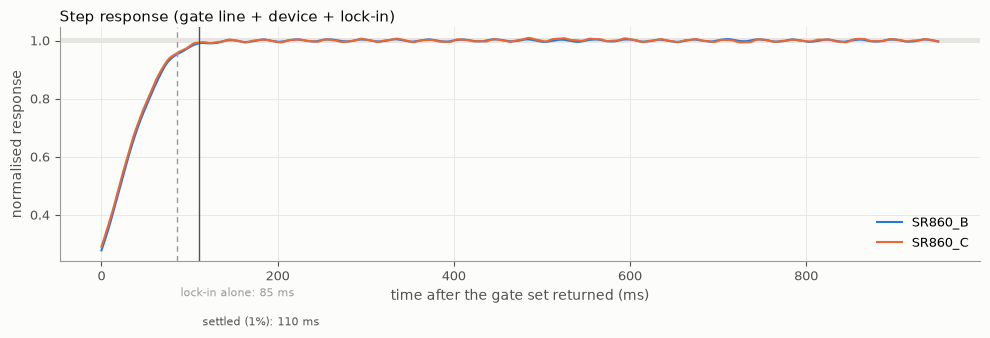

In [12]:
# the gate moves as in the sweep (5 mV chunks, fast_ramp): pick a step like a sweep point
# (one or a few increments) that still changes R clearly
with dm.fast_ramp(Kbg2.volt):
    st = s.step_response(Kbg2.volt, 0.0, 0.05)    # V
st.plot();

In [13]:
# normal (measureme): lock-ins as set, wait `delay` after each step, read once
with dm.fast_ramp(Kbg2.volt):     # same 5 mV chunks, one *OPC? per point
    old_up   = s.sweep(Kbg2.volt, Vbg, delay=0.6)
    old_down = s.sweep(Kbg2.volt, Vbg[::-1], delay=0.6)

2026-11-23 19:04:11,873 [INFO] Starting sweep with ID 2


2026-11-23 19:04:11,873 [INFO] Minimum duration 0h 0m 24s


  0%|          | 0/41 [00:00<?, ?it/s]

  2%|▏         | 1/41 [00:02<01:26,  2.15s/it]

  5%|▍         | 2/41 [00:02<00:50,  1.29s/it]

  7%|▋         | 3/41 [00:03<00:38,  1.02s/it]

... (84 outputs left out)

100%|██████████| 41/41 [00:28<00:00,  1.44it/s]

100%|██████████| 41/41 [00:28<00:00,  1.45it/s]

2026-11-23 19:05:10,136 [INFO] Completed in 0h 0m 28s


2026-11-23 19:05:10,137 [INFO] Data saved in ./data_sim\3\data.tsv.gz


In [14]:
# streamed: same station, same followed parameters
kw = dict(
    dwell=0.3,          # s   averaged per point
    settle=st.settle,   # s   skipped after each step (measured above; None = lock-in settling + 1 period)
    window='hann',      #     'hann' or 'boxcar'
    tau=None,           # s   None = largest SR860 value <= 1/(30 f)
    slope=24, advanced=None, sync=True,
)
with dm.fast_ramp(Kbg2.volt):
    new_up   = s.stream_sweep(Kbg2.volt, Vbg, **kw)
    new_down = s.stream_sweep(Kbg2.volt, Vbg[::-1], **kw)

2026-11-23 19:05:10,142 [INFO] Starting stream_sweep with ID 4


2026-11-23 19:05:10,142 [INFO] tau 0.001 s, settle 110 ms, dwell 0.3 s hann; minimum duration 0h 0m 16s


  0%|          | 0/41 [00:00<?, ?it/s]

  2%|▏         | 1/41 [00:00<00:17,  2.31it/s]

  5%|▍         | 2/41 [00:00<00:18,  2.12it/s]

  7%|▋         | 3/41 [00:01<00:18,  2.06it/s]

... (84 outputs left out)

100%|██████████| 41/41 [00:20<00:00,  2.00it/s]

100%|██████████| 41/41 [00:20<00:00,  2.01it/s]

2026-11-23 19:05:56,591 [INFO] Completed in 0h 0m 23s


2026-11-23 19:05:56,591 [INFO] Data saved in ./data_sim\5\data.tsv.gz


Step response: set call 72 ms; settled to 1% 108 ms after it returned (lock-in filter alone: 85 ms)
  SR860_B: 108 ms
  SR860_C: 108 ms
-> use settle=0.11 in stream_sweep


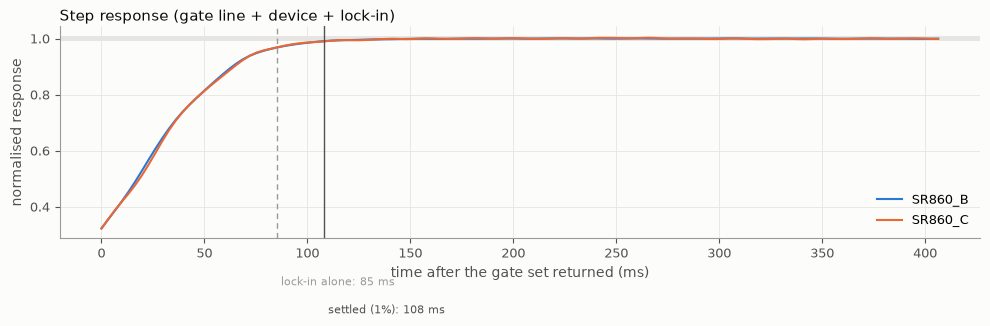

In [15]:
# the same measured from the streamed sweep's own steps; if it needs more settle than was used,
# dm.refilter(new_up.id, settle=...) re-averages the saved stream
dm.step_response(new_up.id).plot();

run                     ms/point |  SR860_B noise  fwd/rev |  SR860_C noise  fwd/rev
2: sweep ↑                   729 |         0.331%    40.8% |         0.224%      30%
3: sweep ↓                   692 |         0.351%    40.6% |         0.251%    30.1%
4: stream_sweep ↑            566 |         0.384%  0.0367% |          0.23%   0.195%
5: stream_sweep ↓            566 |         0.354%  0.0367% |         0.198%   0.195%
noise = point-to-point scatter around a local fit; fwd/rev = rms difference between up and down sweeps of the same kind (lag/smearing + noise; ~1.4x the noise without lag); both relative to the median value


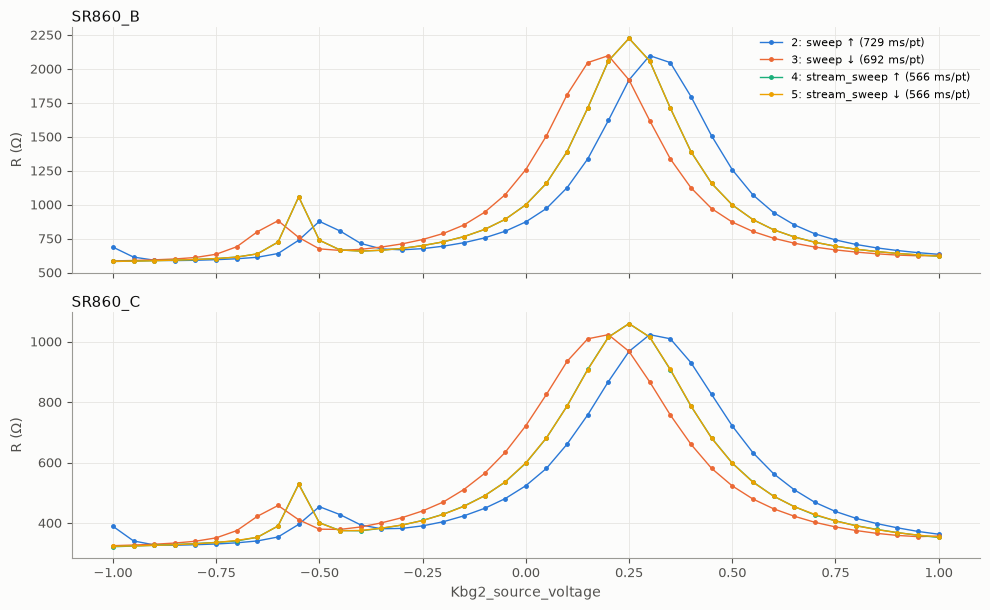

In [16]:
dm.compare([old_up.id, old_down.id, new_up.id, new_down.id], current='SR860_A');

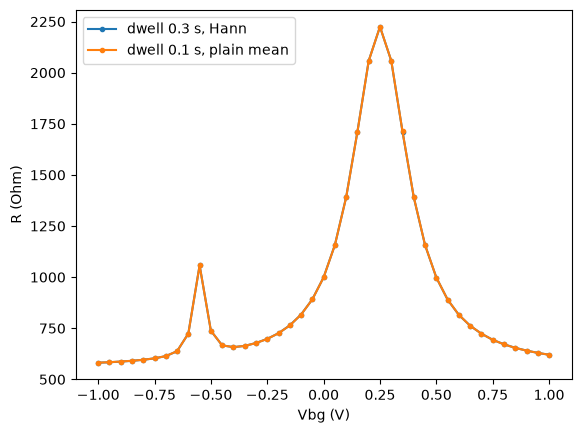

In [17]:
# the raw stream is saved with the run: re-average the same data, no re-measuring
d = dm.refilter(new_up.id, dwell=0.1, window='boxcar')      # same format as sweep_load.pload1d
R = lambda d, n: np.real((d[n + '_X'] + 1j * d[n + '_Y']) / (d['SR860_A_X'] + 1j * d['SR860_A_Y']))
d0 = dm.refilter(new_up.id)                                  # the original averaging
plt.plot(d0['xs'], R(d0, 'SR860_B'), '.-', label='dwell 0.3 s, Hann')
plt.plot(d['xs'], R(d, 'SR860_B'), '.-', label='dwell 0.1 s, plain mean')
plt.xlabel('Vbg (V)'); plt.ylabel('R (Ohm)'); plt.legend();

## 5. Streamed gate map

`s.stream_megasweep` is `s.megasweep` with each fast line streamed:
```python
s.stream_megasweep(Kbg2.volt, np.linspace(-2.25, 5.5, 21), Ktg2.volt, np.linspace(-6, 6, 21),
                   slow_delay=0.5, dwell=0.3, settle=None, window='hann')
```

2026-11-23 19:05:57,069 [INFO] Starting stream_megasweep with ID 6


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  5%|▍         | 1/21 [00:00<00:06,  3.10it/s]

 10%|▉         | 2/21 [00:01<00:11,  1.64it/s]

 14%|█▍        | 3/21 [00:01<00:12,  1.42it/s]

... (64 outputs left out)

100%|██████████| 3/3 [01:32<00:00, 31.92s/it]

100%|██████████| 3/3 [01:32<00:00, 30.85s/it]

2026-11-23 19:07:29,636 [INFO] Completed in 0h 1m 32s


2026-11-23 19:07:29,636 [INFO] Data saved in ./data_sim\6\data.tsv.gz


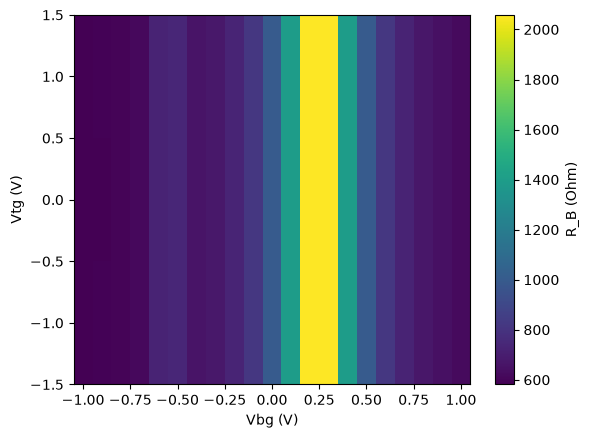

In [18]:
m = s.stream_megasweep(Ktg2.volt, np.linspace(-1, 1, 3), Kbg2.volt, np.linspace(-1, 1, 21),
                       slow_delay=0.5, dwell=0.2)
d = dm.refilter(m.id)     # the run's data, like sweep_load.pload2d
plt.pcolormesh(d['xs'], d['ys'], d['SR860_B_X'] / d['SR860_A_X'], shading='nearest')
plt.xlabel('Vbg (V)'); plt.ylabel('Vtg (V)'); plt.colorbar(label='R_B (Ohm)');